In [1]:
# Importation des librairies nécessaires

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from scipy.stats import chisquare
from scipy.stats import chi2_contingency
from scipy.stats import ks_2samp
from scipy.stats import kruskal
from PIL import Image

In [2]:
# Chargement des fichiers CSV et premières visualisations des dataframes

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 300)

X_train_Rakuten=pd.read_csv('/Users/edernpamart/Desktop/FORMATION DATA SCIENTIST - LIORA /PROJET/data/X_train_update.csv',index_col=0)
print(X_train_Rakuten.shape)
print(X_train_Rakuten.columns.tolist())
print(X_train_Rakuten.head(30))
X_test_Rakuten=pd.read_csv('/Users/edernpamart/Desktop/FORMATION DATA SCIENTIST - LIORA /PROJET/data/X_test_update.csv',index_col=0)
print(X_test_Rakuten.shape)
print(X_test_Rakuten.columns.tolist())
print(X_test_Rakuten.head(30))
Y_train_CVw08PX=pd.read_csv('/Users/edernpamart/Desktop/FORMATION DATA SCIENTIST - LIORA /PROJET/data/Y_train_CVw08PX.csv',index_col=0)
print(Y_train_CVw08PX.shape)
print(Y_train_CVw08PX.columns.tolist())
print(Y_train_CVw08PX.head(30))

nb_image_train=len(list(Path("images/image_train").glob("*.jpg")))
print(nb_image_train)
nb_image_test=len(list(Path("images/image_test").glob("*.jpg")))
print(nb_image_test)

(84916, 4)
['designation', 'description', 'productid', 'imageid']
                                          designation                                        description   productid     imageid
0   Olivia: Personalisiertes Notizbuch / 150 Seite...                                                NaN  3804725264  1263597046
1   Journal Des Arts (Le) N° 133 Du 28/09/2001 - L...                                                NaN   436067568  1008141237
2   Grand Stylet Ergonomique Bleu Gamepad Nintendo...  PILOT STYLE Touch Pen de marque Speedlink est ...   201115110   938777978
3   Peluche Donald - Europe - Disneyland 2000 (Mar...                                                NaN    50418756   457047496
4                                La Guerre Des Tuques  Luc a des id&eacute;es de grandeur. Il veut or...   278535884  1077757786
5   Afrique Contemporaine N° 212 Hiver 2004 - Doss...                                                NaN     5862738   393356830
6          Christof E: Bildungs

In [3]:
# Description générale des dataframes X_train_Rakuten, X_test_Rakuten et Y_train_CVw08PX

print(X_train_Rakuten.describe(include="all"))
print(X_test_Rakuten.describe(include="all"))
print(Y_train_CVw08PX.describe(include="all"))
print(X_train_Rakuten.info())
print(X_test_Rakuten.info())
print(Y_train_CVw08PX.info())


                                              designation                                        description     productid       imageid
count                                               84916                                              55116  8.491600e+04  8.491600e+04
unique                                              82265                                              47506           NaN           NaN
top     5d Broderie Peintures Strass Diamant Bricolage...  <br>Attention !!! Ce produit est un import  si...           NaN           NaN
freq                                                   76                                                252           NaN           NaN
mean                                                  NaN                                                NaN  2.555468e+09  1.152691e+09
std                                                   NaN                                                NaN  1.588656e+09  1.751427e+08
min                                      

In [4]:
#Vérification des doublons dans les colonnes designation des datagrame X_train_Rakuten et X_test_Rakuten    

print(X_train_Rakuten.duplicated(subset=["designation"]).sum())
print(X_test_Rakuten.duplicated(subset=["designation"]).sum())

2651
131


In [5]:
#Vérification valeurs manquantes dans les colonnes designation

print(X_train_Rakuten["designation"].isna().sum())
print(X_test_Rakuten["designation"].isna().sum())

0
0


In [6]:
#Vérification des valeurs manquantes dans les colones description

print(X_train_Rakuten["description"].isna().sum())
print(X_test_Rakuten["description"].isna().sum())

29800
4886


In [7]:
# Différences des longueurs de chaines de caractères entre les colonne désignation et description des dataframes X_train_Rakuten et X_test_Rakuten

tableau_compare_len = pd.concat({
    "designation_train": X_train_Rakuten["designation"].str.len().describe(),
    "description_train": X_train_Rakuten["description"].str.len().describe(),
    "designation_test":  X_test_Rakuten["designation"].str.len().describe(),
    "description_test":  X_test_Rakuten["description"].str.len().describe(),
}, axis=1)

print(tableau_compare_len)

       designation_train  description_train  designation_test  description_test
count       84916.000000       55116.000000      13812.000000       8926.000000
mean           70.163303         808.171692         69.859325        813.389760
std            36.793383         805.462153         36.711585        854.631118
min            11.000000           1.000000         11.000000          1.000000
25%            43.000000         259.000000         43.000000        249.000000
50%            64.000000         626.000000         64.000000        616.000000
75%            90.000000        1034.000000         90.000000       1051.000000
max           250.000000       12451.000000        250.000000      22299.000000


In [8]:
# Analyser la distributions des produits de e-commerce Rakuten en fonction de leur classe dans Y_train_CVw08PX

nb_classes=Y_train_CVw08PX["prdtypecode"].nunique()
print(f"Le nombre de classe est {nb_classes}")
produits_par_classe_=Y_train_CVw08PX["prdtypecode"].value_counts().sort_values(ascending=False).reset_index()
produits_par_classe_.columns = ["prdtypecode", "nb_produits"]
print(produits_par_classe_)

Le nombre de classe est 27
    prdtypecode  nb_produits
0          2583        10209
1          1560         5073
2          1300         5045
3          2060         4993
4          2522         4989
5          1280         4870
6          2403         4774
7          2280         4760
8          1920         4303
9          1160         3953
10         1320         3241
11           10         3116
12         2705         2761
13         1140         2671
14         2582         2589
15           40         2508
16         2585         2496
17         1302         2491
18         1281         2070
19           50         1681
20         2462         1421
21         2905          872
22           60          832
23         2220          824
24         1301          807
25         1940          803
26         1180          764


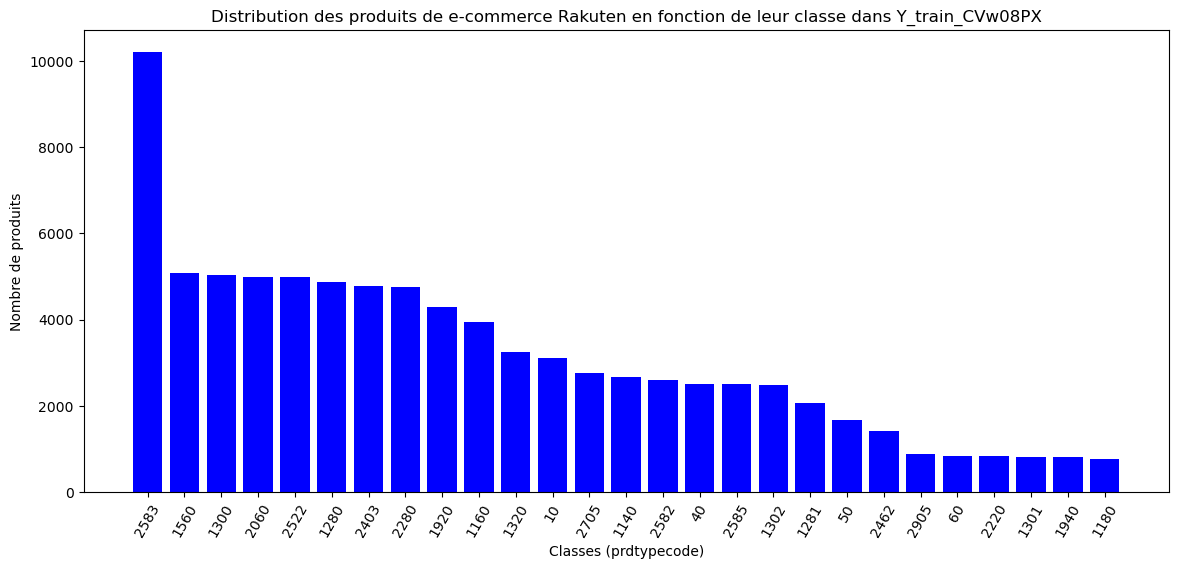

In [9]:
#Représentation graphique de la distribution des produits de e-commerce Rakuten en fonction de leur classe dans Y_train_CVw08PX

x=np.arange(len(produits_par_classe_))
plt.figure(figsize=(14, 6))
plt.bar(x, produits_par_classe_["nb_produits"], color='blue')
plt.title('Distribution des produits de e-commerce Rakuten en fonction de leur classe dans Y_train_CVw08PX')
plt.xlabel('Classes (prdtypecode)')
plt.ylabel('Nombre de produits')
plt.xticks(x, produits_par_classe_["prdtypecode"].astype(str), rotation=60)
plt.show()

In [10]:
#Test statistique Khi2 d'adéquation pour vérifier si la distribution des classes est uniforme

nb_produits_ = produits_par_classe_["nb_produits"]
chi2_stat, p_value = chisquare(nb_produits_)
print(f"Chi-squared statistic: {chi2_stat}, p-value: {p_value}")
if p_value < 0.05:
    print("La distribution des classes n'est pas uniforme et au moins une classe s'écarte de la distribution uniforme (rejette H0)")
else:
    print("La distribution des classes est uniforme (ne rejette pas H0)")       

Chi-squared statistic: 36570.33402421217, p-value: 0.0
La distribution des classes n'est pas uniforme et au moins une classe s'écarte de la distribution uniforme (rejette H0)


In [11]:
# Pourcentage de descriptions manquantes par classe de produit dans le dataframe X_train_Rakuten

description_code = X_train_Rakuten[["description"]].join(Y_train_CVw08PX)
print(f"Le nombre de descriptions manquantes est: {description_code['description'].isna().sum()}")
pourcentage = description_code.groupby("prdtypecode")["description"].apply(lambda s: s.isna().mean() * 100).sort_values()
print(pourcentage)

Le nombre de descriptions manquantes est: 29800
prdtypecode
2905     0.000000
2582     2.394747
1560     3.489060
1920     4.810597
1940     5.603985
2060     5.728019
2585     7.932692
2220     8.009709
2583     8.845137
1302    11.120032
1301    13.011152
60      15.985577
1280    21.930185
1300    23.250743
1281    23.768116
2522    23.832431
50      28.316478
1320    33.970997
2705    37.124230
1140    64.619993
40      65.470494
1180    79.973822
10      89.152760
1160    91.171262
2280    93.277311
2462    96.270232
2403    97.360704
Name: description, dtype: float64


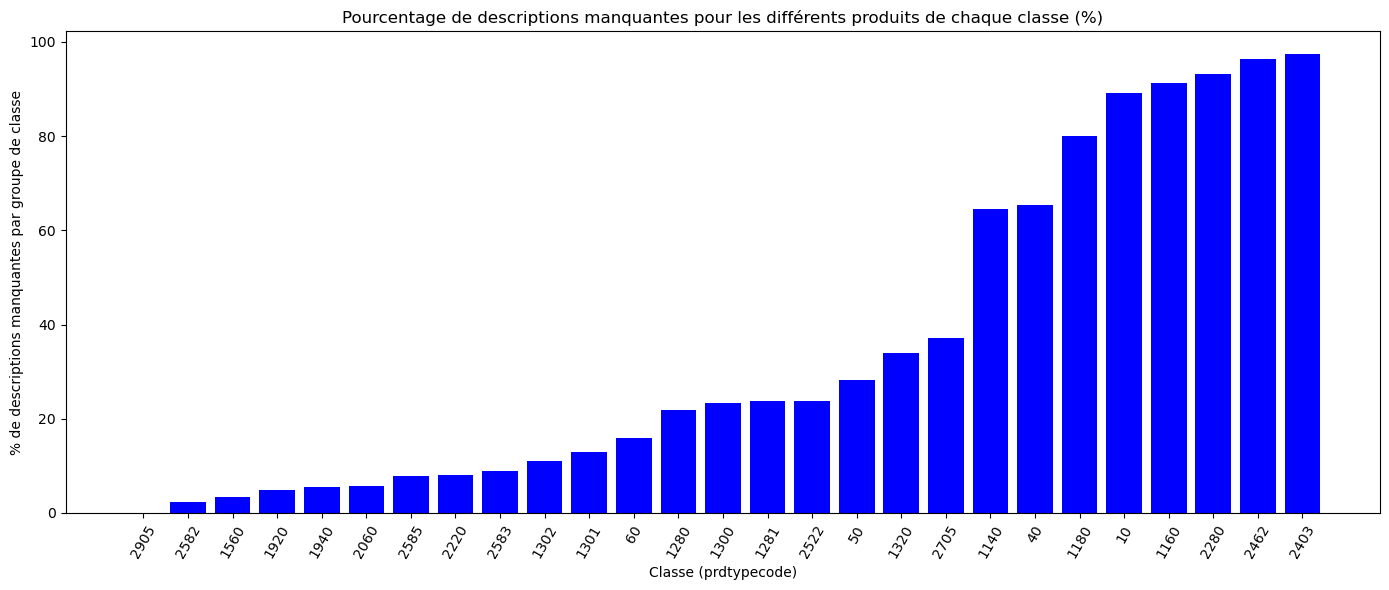

In [12]:
# Représentation graphique du pourcentage de descriptions manquantes par classe de produit dans le dataframe X_train_Rakuten

plt.figure(figsize=(14, 6))
plt.bar(pourcentage.index.astype(str), pourcentage.values, color="blue")
plt.title("Pourcentage de descriptions manquantes pour les différents produits de chaque classe (%)")
plt.xlabel("Classe (prdtypecode)")
plt.ylabel("% de descriptions manquantes par groupe de classe")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

In [13]:
#Test statistique Khi2 d'indépendance pour vérifier si la présence de description est indépendante de la classe de produit

contingency_table = pd.crosstab(description_code["prdtypecode"], description_code["description"].notna())
chi2_stat, p_value, dof, expected = chi2_contingency(contingency_table)
print(f"Chi-squared statistic: {chi2_stat}, p-value: {p_value}")
if p_value < 0.05:
    print("Il existe une dépendance significative entre la classe et la présence de description (rejette H0)")
else:
    print("Il n'existe pas de dépendance significative entre la classe et la présence de description (ne rejette pas H0)")

Chi-squared statistic: 43757.76572143289, p-value: 0.0
Il existe une dépendance significative entre la classe et la présence de description (rejette H0)


In [14]:
# Comparaison de la distribution des jeux de données train et test pour la variable 'designation'

train_len = X_train_Rakuten["designation"].str.len().dropna()
test_len = X_test_Rakuten["designation"].str.len().dropna()

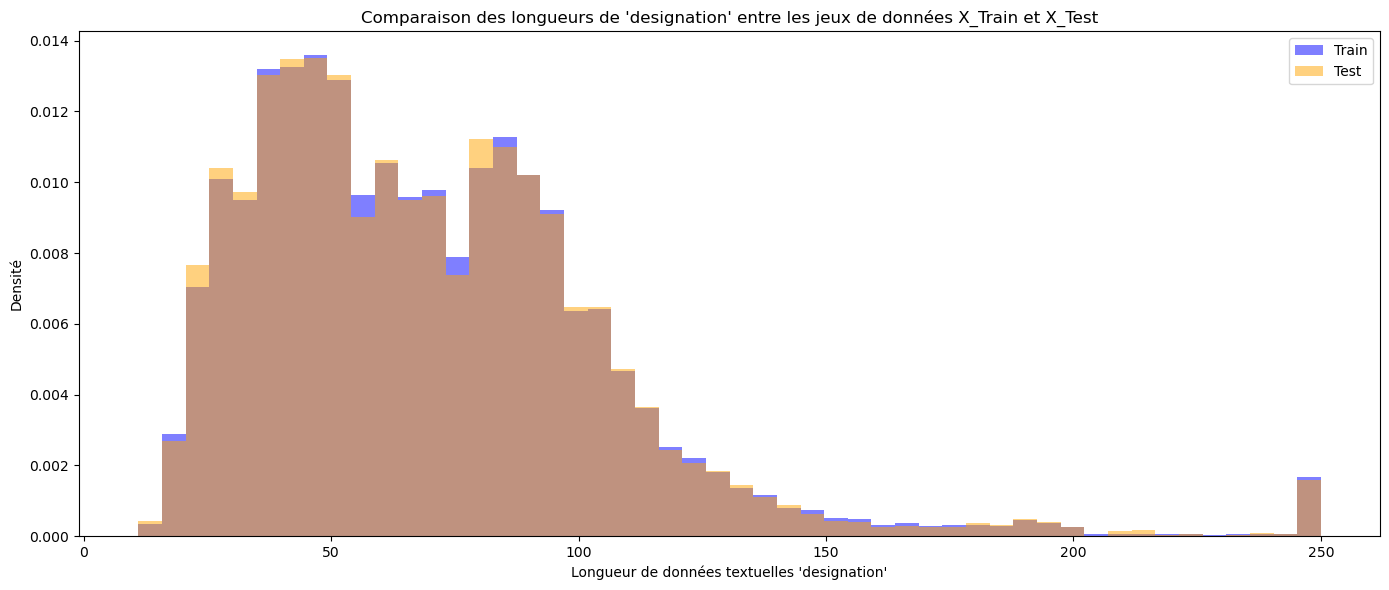

In [15]:
# Représentation graphique de la distribution des longueurs de 'designation' entre les jeux de données X_Train et X_Test

plt.figure(figsize=(14, 6))
plt.hist(train_len, bins=50, alpha=0.5, label="Train", color="blue",density=True)
plt.hist(test_len, bins=50, alpha=0.5, label="Test", color="orange",density=True)
plt.title("Comparaison des longueurs de 'designation' entre les jeux de données X_Train et X_Test")
plt.xlabel("Longueur de données textuelles 'designation'")
plt.ylabel("Densité")
plt.legend()
plt.tight_layout()
plt.show()  

In [16]:
# Test statitsitque Kolmogorov-Smirnov pour vérifier si la distribution des longueurs de designation est similaire entre les jeux de données train et test

ks_stat, p_value = ks_2samp(train_len, test_len)
print(f"KS statistic: {ks_stat}, p-value: {p_value}")
if p_value < 0.05:
    print("Les distributions des longueurs de 'designation' entre les jeux de données Train et Test sont significativement différentes (rejette H0)")
else:
    print("Les distributions des longueurs de 'designation' entre les jeux de données Train et Test ne sont pas significativement différentes (ne rejette pas H0)") 


KS statistic: 0.006946102215771077, p-value: 0.6126818378399331
Les distributions des longueurs de 'designation' entre les jeux de données Train et Test ne sont pas significativement différentes (ne rejette pas H0)


In [17]:
#Analyse des Longueurs des designation produits par classes

designations_par_classes = X_train_Rakuten[["designation"]].join(Y_train_CVw08PX)
print(designations_par_classes.head(10))
longueurs_moyennes_designations = designations_par_classes.groupby("prdtypecode")["designation"].apply(lambda s: s.str.len().mean()).sort_values(ascending=False).reset_index()
longueurs_moyennes_designations.columns = ["prdtypecode", "longueur_moyenne_designation"]

                                         designation  prdtypecode
0  Olivia: Personalisiertes Notizbuch / 150 Seite...           10
1  Journal Des Arts (Le) N° 133 Du 28/09/2001 - L...         2280
2  Grand Stylet Ergonomique Bleu Gamepad Nintendo...           50
3  Peluche Donald - Europe - Disneyland 2000 (Mar...         1280
4                               La Guerre Des Tuques         2705
5  Afrique Contemporaine N° 212 Hiver 2004 - Doss...         2280
6         Christof E: Bildungsprozessen Auf Der Spur           10
7  Conquérant Sept Cahier Couverture Polypro 240 ...         2522
8          Puzzle Scooby-Doo Avec Poster 2x35 Pieces         1280
9  Tente Pliante V3s5-Pro Pvc Blanc - 3 X 4m50 - ...         2582


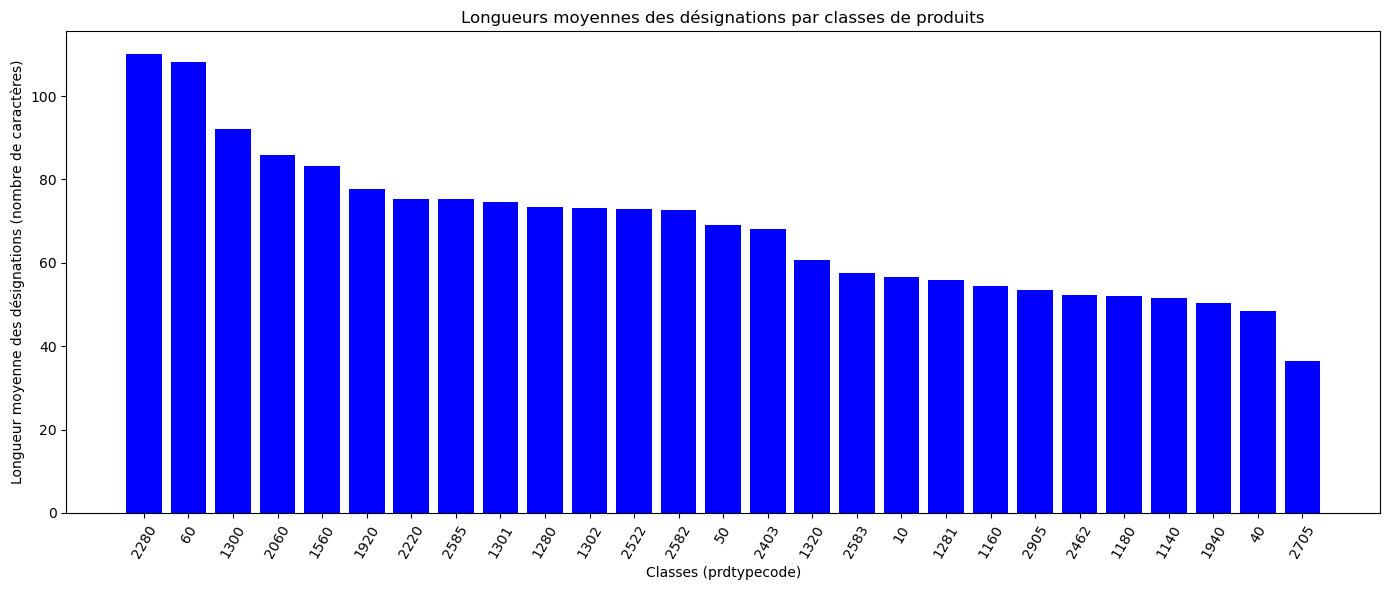

In [18]:
# Representation graphique des longueurs moyennes des désignations par classes de produits

plt.figure(figsize=(14, 6))
plt.bar(longueurs_moyennes_designations.index.astype(str), longueurs_moyennes_designations["longueur_moyenne_designation"], color="blue")
plt.title("Longueurs moyennes des désignations par classes de produits")
plt.xlabel("Classes (prdtypecode)")
plt.ylabel("Longueur moyenne des désignations (nombre de caractères)")
plt.xticks(x, longueurs_moyennes_designations.prdtypecode.astype(str), rotation=60)
plt.tight_layout()
plt.show()

In [19]:
# Test statistique kruskal-wallis pour vérifier si les longueurs de designation diffèrent significativement entre les classes

grouped_designations = [group["designation"].dropna().str.len() for name, group in designations_par_classes.groupby("prdtypecode")]
kruskal_stat, p_value = kruskal(*grouped_designations)
print(f"Kruskal-Wallis statistic: {kruskal_stat}, p-value: {p_value}")
if p_value < 0.05:
    print("Les longueurs de 'designation' diffèrent significativement entre les classes (rejette H0)")
else:
    print("Les longueurs de 'designation' ne diffèrent pas significativement entre les classes (ne rejette pas H0)")

Kruskal-Wallis statistic: 19025.282639075194, p-value: 0.0
Les longueurs de 'designation' diffèrent significativement entre les classes (rejette H0)


In [20]:
# Exemples d'images pour les différentes classes

df_images = X_train_Rakuten.drop(columns=['designation', 'description']).join(Y_train_CVw08PX)
print(df_images.head(10))
ordre = df_images["prdtypecode"].value_counts().index

exemples = df_images.groupby("prdtypecode").head(1).set_index("prdtypecode").loc[ordre]
print(exemples.head(10))

    productid     imageid  prdtypecode
0  3804725264  1263597046           10
1   436067568  1008141237         2280
2   201115110   938777978           50
3    50418756   457047496         1280
4   278535884  1077757786         2705
5     5862738   393356830         2280
6    91920807   907794536           10
7   344240059   999581347         2522
8  4239126071  1325918866         1280
9  3793572222  1245644185         2582
              productid     imageid
prdtypecode                        
2583         3936362802  1268740880
1560         1915836983  1111840281
1300         3748203527  1240721678
2060         4198487181  1313675704
2522          344240059   999581347
1280           50418756   457047496
2403         3735707499  1239242410
2280          436067568  1008141237
1920         1882164320  1109088140
1160         3226779852  1202890774


(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB
(500, 500)
RGB


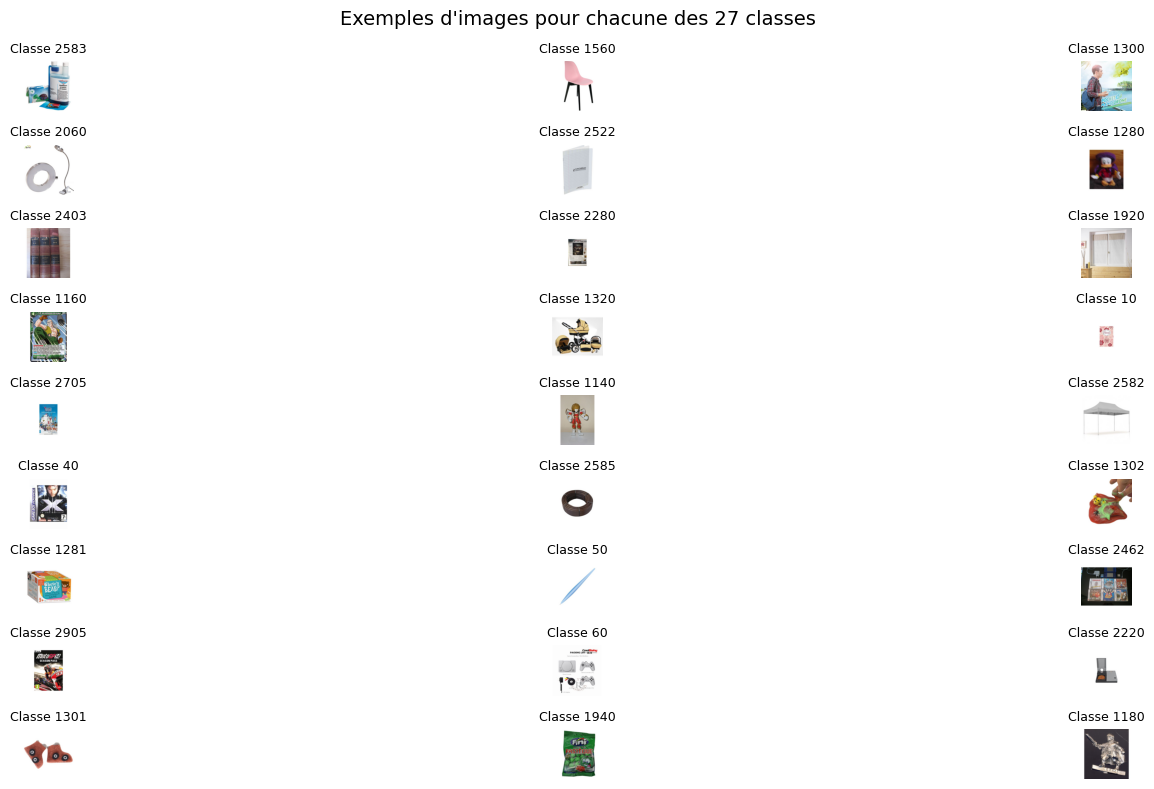

In [21]:
# Représentation graphique des exemples d'images pour les différentes classes

fig, axes = plt.subplots(9, 3, figsize=(20, 8))

for ax, (code, produit) in zip(axes.flat, exemples.iterrows()):
    chemin = f"/Users/edernpamart/Desktop/FORMATION DATA SCIENTIST - LIORA /PROJET/data/images/image_train/image_{produit['imageid']}_product_{produit['productid']}.jpg"
    ax.imshow(Image.open(chemin))
    ax.set_title(f"Classe {code}", fontsize=9)
    ax.axis("off")
    print(Image.open(chemin).size)   
    print(Image.open(chemin).mode)

plt.suptitle("Exemples d'images pour chacune des 27 classes", fontsize=14)
plt.tight_layout()
plt.show()









